# V-JEPA 2.1 dense video features

What changes when a masked video model also learns at visible locations? Train two encoders from identical initial weights and assess their local features with a frozen foreground probe.

This small ablation compares hidden-only final-layer supervision with two components of V-JEPA 2.1 together: a distance-weighted context loss and prediction at two encoder depths. The scene is a moving point on a grid. The experiment does not separate the individual contributions of the two components.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


import copy
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "video_teaching.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")
from gallery.video_teaching import (
    VideoEncoder,
    VideoPredictor,
    advance,
    clips,
    frame,
    region_mask,
    tubelets,
    update_teacher,
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, balanced_accuracy_score, f1_score


def weights_for_context(keep, hide):
    coordinates = torch.cartesian_prod(torch.arange(2), torch.arange(4), torch.arange(4)).float()
    distance = torch.cdist(coordinates[keep], coordinates[hide], p=2).min(1).values
    return distance.rsqrt()


def train_variant(data, dense):
    torch.manual_seed(17)
    net = VideoEncoder()
    teacher = copy.deepcopy(net).eval().requires_grad_(False)
    pred = VideoPredictor(multi_level=dense)
    optimiser = torch.optim.AdamW([*net.parameters(), *pred.parameters()], lr=0.0013)
    data_rng = torch.Generator().manual_seed(71)
    history = []
    for epoch in range(10):
        value = []
        coefficient = 0.5 * min(1, epoch / 4)
        for ids in torch.randperm(len(data), generator=data_rng).split(48):
            keep, hide = region_mask(data_rng)
            batch = data[ids]
            with torch.no_grad():
                targets = teacher(batch)
            guesses = pred(net(batch, keep), keep, hide)
            target_levels = targets if dense else targets[-1:]
            loss = torch.zeros(())
            for output, target in zip(guesses, target_levels):
                masked = F.l1_loss(output[:, len(keep) :], target[:, hide])
                loss = loss + masked
                if dense:
                    ctx = (output[:, : len(keep)] - target[:, keep]).abs().mean(-1)
                    loss = loss + coefficient * (ctx * weights_for_context(keep, hide)).mean()
            loss = loss / len(guesses)
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
            update_teacher(teacher, net)
            value.append((masked.item(), len(batch)))
        history.append(sum(v * n for v, n in value) / len(data))
    return net.eval(), history


@torch.no_grad()
def features(net, data):
    return torch.cat([net(b)[-1] for b in data.split(64)]).numpy()

## Train with matched video samples and masks

The target sees all tubelets. Only visible tubelets enter the student. In the dense variant, the context weight increases over four epochs and is largest next to the mask.

In [2]:
seed()
pre = tubelets(clips(480, 17))
probe = tubelets(clips(192, 83))
test = tubelets(clips(120, 149))
first, base_hist = train_variant(pre, False)
second, dense_hist = train_variant(pre, True)
keep, hide = region_mask(torch.Generator().manual_seed(19))
changed = test[:2].clone()
changed[:, hide] += 10
with torch.no_grad():
    assert torch.equal(second(test[:2], keep)[-1], second(changed, keep)[-1])

## Fit a foreground probe

A tubelet is positive if it contains a pixel near the centre of the rendered point in either frame. The fixed threshold is applied to the original intensities. The logistic probe trains on a separate set of clips, with an independent set for testing.

,Frozen features,Test clips,Positive tubelets,Average precision,Foreground F1,Balanced accuracy
0,Hidden-only,120,312,0.98987,0.95122,0.99546
1,Dense and two levels,120,312,0.99727,0.96445,0.99674


Test foreground prevalence: 0.081


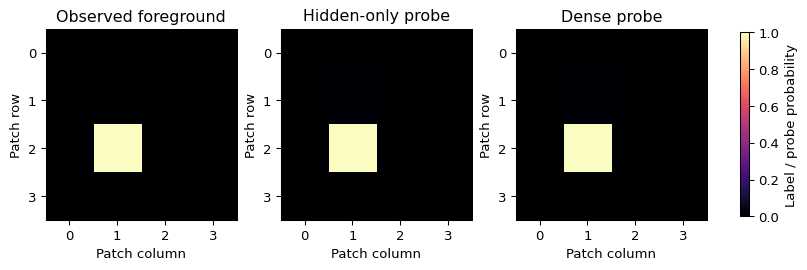

In [3]:
yp = (probe.max(-1).values.numpy() > 0.85).astype(int)
yt = (test.max(-1).values.numpy() > 0.85).astype(int)
rows = []
example_maps = []
for name, net in [("Hidden-only", first), ("Dense and two levels", second)]:
    a, b = features(net, probe), features(net, test)
    model = make_pipeline(
        StandardScaler(), LogisticRegression(C=1, max_iter=600, class_weight="balanced")
    )
    model.fit(a.reshape(-1, a.shape[-1]), yp.ravel())
    scores = model.predict_proba(b.reshape(-1, b.shape[-1]))[:, 1].reshape(yt.shape)
    guess = (scores >= 0.5).astype(int)
    rows.append(
        (
            name,
            len(test),
            int(yt.sum()),
            average_precision_score(yt.ravel(), scores.ravel()),
            f1_score(yt.ravel(), guess.ravel()),
            balanced_accuracy_score(yt.ravel(), guess.ravel()),
        )
    )
    example_maps.append(scores[0, :16].reshape(4, 4))
report(
    [
        "Frozen features",
        "Test clips",
        "Positive tubelets",
        "Average precision",
        "Foreground F1",
        "Balanced accuracy",
    ],
    rows,
)
print(f"Test foreground prevalence: {yt.mean():.3f}")
fig, axes = plt.subplots(1, 3, figsize=(8.4, 2.9), layout="constrained")
for ax, arr, title in zip(
    axes,
    [yt[0, :16].reshape(4, 4), *example_maps],
    ["Observed foreground", "Hidden-only probe", "Dense probe"],
):
    im = ax.imshow(arr, vmin=0, vmax=1, cmap="magma")
    ax.set(
        xticks=range(4), yticks=range(4), xlabel="Patch column", ylabel="Patch row", title=title
    )
fig.colorbar(im, ax=axes, shrink=0.72, label="Label / probe probability")
plt.show()

## Interpreting the result

Of 3,840 held-out tubelets, 312 contained the centre of the moving point. Average precision was 0.990 for the hidden-only model and 0.997 for the dense, two-level model. Both encoders solved most of this simple foreground task.

Read average precision alongside foreground prevalence. The score depends on how well tubelets are ranked, while F1 also depends on the threshold. The first test clip supplies the visual example.

## Exercise

Train a third variant with context supervision at the last layer only. That extra comparison isolates the effect of the second prediction depth.

## References

[Mur-Labadia et al. (2026), V-JEPA 2.1](https://arxiv.org/abs/2603.14482)

[Assran et al. (2025), V-JEPA 2](https://arxiv.org/abs/2506.09985)